# guesser quickstart

This notebook uses the released 8-member ensemble to predict mutation ddG with uncertainty and to explain one prediction with Integrated Gradients.

* **Part 1-2** run anywhere (CPU is fine): they use 41 graph pairs bundled in `examples/` (Ssym single mutants and PTmul multi-mutants).
* **Part 3** predicts for your own structure and mutations. Building graphs needs MadraX (see README).

Sign convention: ddG > 0 means the mutation destabilises the protein (kcal/mol).

In [1]:
import os, sys
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
from guesser.inference import predict, released_weights, metrics
from guesser.features import FEATURE_NAMES

weights = released_weights(os.path.join(ROOT, "weights"))
print(len(weights), "ensemble members:", [os.path.basename(w) for w in weights])

8 ensemble members: ['guesser_S42.pt', 'guesser_S43.pt', 'guesser_S44.pt', 'guesser_S45.pt', 'guesser_S46.pt', 'guesser_S47.pt', 'guesser_S48.pt', 'guesser_S49.pt']


## 1. Ensemble prediction on the bundled example graphs

In [2]:
graphs = torch.load(os.path.join(ROOT, "examples", "example_graphs.pt"), weights_only=False)
ens, members = predict(graphs, weights, device="cpu", return_members=True)
ens[["pdb", "mutation", "num_muts", "true_ddg", "pred_ddg", "intra_epistemic_std", "aleatoric_std", "total_std"]].head(10)

,pdb,mutation,num_muts,true_ddg,pred_ddg,intra_epistemic_std,aleatoric_std,total_std
0,1amq.pdb,"[('A', 'CYS', 191, 'TYR')]",1.0,2.30,1.298733,0.354441,0.013881,0.558603
1,1l63.pdb,"[('A', 'ALA', 73, 'SER')]",1.0,0.40,0.031739,0.210381,0.024268,0.257389
2,1lz1.pdb,"[('A', 'ILE', 59, 'VAL')]",1.0,1.10,1.001933,0.580243,0.024235,0.802420
3,2lzm.pdb,"[('A', 'VAL', 149, 'CYS')]",1.0,2.20,1.024624,0.737472,0.036421,0.925043
4,1ey0.pdb,"[('A', 'PRO', 117, 'ALA')]",1.0,-0.80,1.144531,0.674230,0.031356,0.931454
5,1l63.pdb,"[('A', 'VAL', 111, 'ILE')]",1.0,0.90,-0.270974,0.728949,0.033256,0.774157
6,1rn1.pdb,"[('C', 'GLN', 25, 'LYS')]",1.0,-0.93,-0.469750,0.243064,0.022254,0.295595
7,4lyz.pdb,"[('A', 'GLY', 67, 'ALA')]",1.0,0.50,0.618613,0.249866,0.012967,0.337910
8,1l63.pdb,"[('A', 'ALA', 49, 'SER')]",1.0,0.50,0.731466,0.449832,0.029851,0.480657
9,1lz1.pdb,"[('A', 'VAL', 2, 'MET')]",1.0,0.20,-0.077795,0.665660,0.036722,0.675410


Columns:

* `pred_ddg`: ensemble mean of mu = gamma_phys + gamma_base + gamma_epi
* `intra_epistemic_std`: sqrt of the mean NIG epistemic variance beta / (v (alpha - 1)), the paper's sigma_e
* `inter_epistemic_std`: spread of mu between the 8 members
* `aleatoric_std`: sqrt of the mean beta / (alpha - 1)
* `pred_phys`, `pred_base`, `pred_epi`: the three additive parts of the prediction

{'N': 41, 'PCC': 0.5310574173927307, 'Spearman': 0.52894527513318, 'RMSE': 1.0294690132141113, 'MAE': 0.7133196592330933, 'Spearman_err_sigma': -0.0019163763066202095}


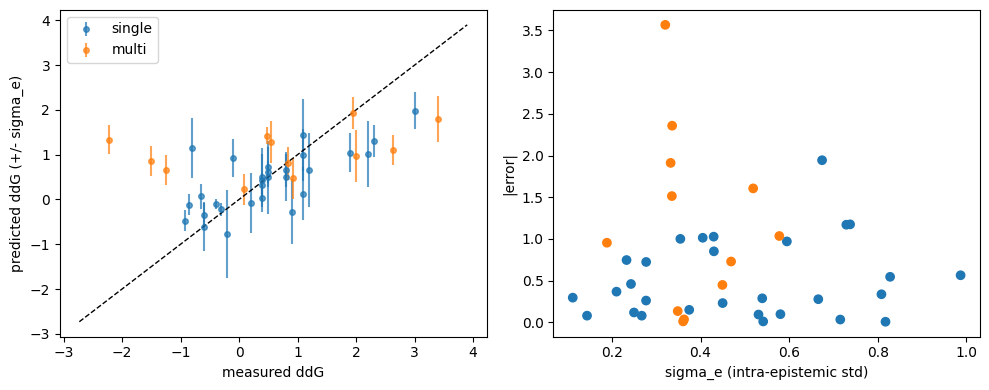

In [3]:
print(metrics(ens, sigma="intra_epistemic_std"))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
multi = ens.num_muts > 1
for sel, lab in ((~multi, "single"), (multi, "multi")):
    ax[0].errorbar(ens.true_ddg[sel], ens.pred_ddg[sel], yerr=ens.intra_epistemic_std[sel], fmt="o", ms=4, alpha=.7, label=lab)
lim = [min(ens.true_ddg.min(), ens.pred_ddg.min()) - .5, max(ens.true_ddg.max(), ens.pred_ddg.max()) + .5]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlabel="measured ddG", ylabel="predicted ddG (+/- sigma_e)"); ax[0].legend()
ax[1].scatter(ens.intra_epistemic_std, (ens.pred_ddg - ens.true_ddg).abs(), c=multi.map({False: "C0", True: "C1"}))
ax[1].set(xlabel="sigma_e (intra-epistemic std)", ylabel="|error|")
plt.tight_layout()

### Antisymmetry
Each member also predicts the reverse mutation (MT -> WT). A thermodynamically consistent model gives ddG(rev) = -ddG(fwd).

In [4]:
m = members[0]
fwd, rev = m[m.direction == "Forward"].reset_index(drop=True), m[m.direction == "Reverse"].reset_index(drop=True)
print("member S42: mean |ddG_fwd + ddG_rev| =", float((fwd.pred_ddg + rev.pred_ddg).abs().mean()))

member S42: mean |ddG_fwd + ddG_rev| = 0.49091050028800964


## 2. Explaining one prediction (Integrated Gradients)

The mutation attribution integrates the gradient along x_diff from 0 (no mutation) to the actual mutant, keeping the wild-type features fixed. Summed over nodes, the 23 per-feature contributions add up to mu(WT, MT) - mu(WT, WT), up to the quadrature residual. Averaging the attributions of the 8 members gives exactly the attribution of the ensemble mean.

1A23.pdb [('A', 'CYS', 30, 'SER'), ('A', 'CYS', 33, 'SER')]
predicted ddG 0.964 = null-mutation baseline -0.715 + sum of feature contributions 1.681


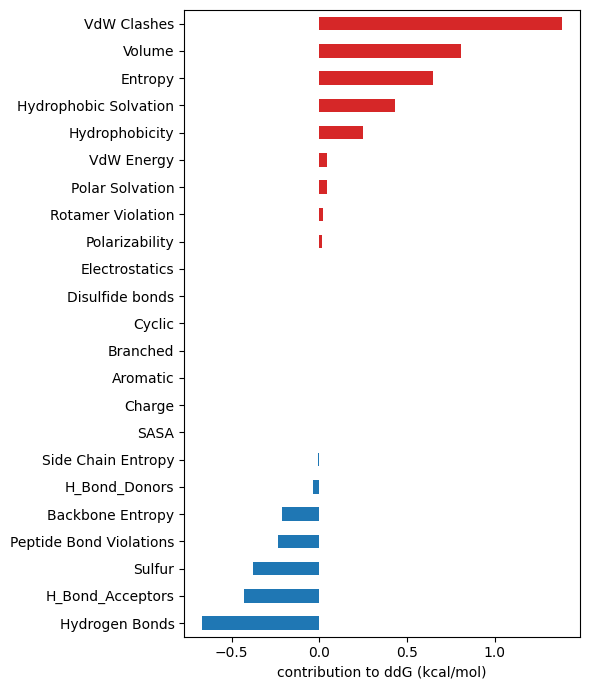

In [5]:
from torch_geometric.data import Batch
from guesser.explain.core import explain_batch, load_explain_model

i = int(np.argmax(ens.num_muts.values > 1))  # first multi-mutant
g_wt, g_mt = graphs[i]["graph_pair"]
bw, bm = Batch.from_data_list([g_wt]), Batch.from_data_list([g_mt])
attr, f_mt, f_null = [], [], []
for w in weights:
    model = load_explain_model(w, 23, torch.device("cpu"), torch.float64)
    per_graph, direct, _ = explain_batch(model, bw, bm, n_steps=32, fast=True, max_nodes_per_pass=5000)
    attr.append(per_graph[0]["signed_attr_mu"])
    f_mt.append(per_graph[0]["f_mut_mu"]); f_null.append(per_graph[0]["f0_mut_mu"])
A = np.mean(attr, axis=0)                     # [n_nodes, 23]
contrib = pd.Series(A.sum(axis=0), index=FEATURE_NAMES).sort_values()
print(graphs[i]["pdb"], graphs[i]["mutation"])
print(f"predicted ddG {np.mean(f_mt):.3f} = null-mutation baseline {np.mean(f_null):.3f} "
      f"+ sum of feature contributions {contrib.sum():.3f}")
contrib.plot.barh(figsize=(6, 7), color=["C3" if v > 0 else "C0" for v in contrib]); plt.xlabel("contribution to ddG (kcal/mol)"); plt.tight_layout()

In [6]:
# Where in the neighbourhood: per-node attribution (sum over features); mutated nodes first
node = pd.DataFrame({"node": range(A.shape[0]), "mutated": g_wt.mut_mask.numpy(), "attribution": A.sum(axis=1)})
node.sort_values(["mutated", "attribution"], ascending=[False, False], key=lambda s: s.abs() if s.name == "attribution" else s).head(10)

,node,mutated,attribution
9,9,True,0.945703
6,6,True,0.713476
4,4,False,0.011045
3,3,False,-0.007874
10,10,False,0.006867
7,7,False,0.005603
23,23,False,0.004778
25,25,False,0.000931
26,26,False,-0.000873
2,2,False,0.000807


For the paper's benchmark sets the full per-residue explanations are released as HDF5 files on Zenodo. Read them with `guesser.explain.h5.ExplanationFile` (`ef.summary()`, `ef.mutation(i)`, `ef.node_array("signed_attr_mu", i)`).

## 3. Your own structure (needs MadraX)

Give a PDB file and mutations as `A:L45F`, `L45F` (chain from `chain=`) or `A:L45F+A:G50A` for a multi-mutant.

In [7]:
from guesser.structure import MADRAX_AVAILABLE
from guesser.graphs import build_graphs, mutation_table, check_graphs

PDB_FILE = os.path.join(ROOT, "examples", "my_protein.pdb")   # <- change
MUTATIONS = ["A:L45F", "A:G50A", "A:L45F+A:G50A"]               # <- change

if MADRAX_AVAILABLE and os.path.exists(PDB_FILE):
    df = mutation_table(os.path.basename(PDB_FILE), MUTATIONS, default_chain="A")
    my_graphs = build_graphs(df, os.path.dirname(PDB_FILE), radii=[9.0], edge_cutoff=9.0)[9.0]
    check_graphs(my_graphs)
    display(predict(my_graphs, weights)[["mutation", "pred_ddg", "intra_epistemic_std", "total_std"]])
else:
    print("Skipped: needs MadraX installed and PDB_FILE set (MadraX available: %s)" % MADRAX_AVAILABLE)

Skipped: needs MadraX installed and PDB_FILE set (MadraX available: False)


The same from the command line:

```bash
guesser predict --pdb my_protein.pdb --mutations A:L45F A:G50A A:L45F+A:G50A --out preds.csv
```